# 04 - Modelo Multimodal (imagem + texto)\n\nProdutor de previsoes. Corre em **GPU**. Combina o ramo visual (ResNet50 congelada) com embeddings BERTimbau dos relatorios clinicos, reconstruindo os conjuntos a partir de `split_indices.npz`.


In [ ]:
# Importacoes -- Modelo multimodal (imagem + texto) (GPU).
import os, re, random, pickle
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from transformers import AutoTokenizer, AutoModel
import nltk
from nltk.corpus import stopwords
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay


In [ ]:
# Bootstrap: deteta Colab vs local, monta o Drive se necessario e coloca o repo
# no sys.path. Arranque duplicado inline por necessidade: nao e possivel
# "from src import ..." antes do mount em Colab.
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    import sys
    sys.path.insert(0, '/content/drive/MyDrive/ophthalmic-referral-cnn')
except ImportError:
    import os, sys
    sys.path.insert(0, os.getcwd())

from src import bootstrap, data, viz

IN_COLAB = bootstrap.setup()
REPO_DIR = bootstrap.get_repo_dir(IN_COLAB)
DATA_DIR = bootstrap.get_data_dir(IN_COLAB, REPO_DIR)
base_dir = str(DATA_DIR)


In [ ]:
# Reprodutibilidade: sementes fixas em todas as fontes de aleatoriedade.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)


In [ ]:
# Carregamento do dataset (mesma ordem determinista de src/data.py).
X_original, y, nomes_ficheiros, labels_ficheiros, folders = data.load_dataset(DATA_DIR)
print("X_original:", X_original.shape, "| y:", y.shape)


In [ ]:
# Diretorios de artefactos -- sempre em Drive (derivam de REPO_DIR).
ARTIFACT_DIRS = bootstrap.get_artifact_dirs(REPO_DIR)
ARTIFACTS_DIR = ARTIFACT_DIRS["artifacts"]
MODELS_DIR    = ARTIFACT_DIRS["models"]
PREDS_DIR     = ARTIFACT_DIRS["preds"]
HISTORY_DIR   = ARTIFACT_DIRS["history"]
for _d in (MODELS_DIR, PREDS_DIR, HISTORY_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Artefactos em:", ARTIFACTS_DIR)


In [ ]:
# Reconstrucao dos indices do split (committed). Transfer learning usa pixels em
# [0,255]; cada base aplica o seu proprio pre-processamento interno.
split = data.load_split_indices(ARTIFACTS_DIR / "split_indices.npz")
trainval_idx, test_idx = split["trainval_idx"], split["test_idx"]
train_idx, val_idx = split["train_idx"], split["val_idx"]
y = y.astype(int)
y_test = y[test_idx]
class_names = data.CLASS_NAMES


In [ ]:
# Ramo de imagem: mesmos conjuntos [0,255] do transfer learning.
X_train_tl = X_original[train_idx].astype("float32")
X_val_tl   = X_original[val_idx].astype("float32")
X_test_tl  = X_original[test_idx].astype("float32")
y_train_tl = y[train_idx]
y_val_tl   = y[val_idx]


In [ ]:
# Pesos de classe (identicos aos das CNNs: mesma particao de treino).
classes = np.unique(y_train_tl)
pesos = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_tl)
class_weight = {int(c): float(w) for c, w in zip(classes, pesos)}
print("Pesos por classe:", class_weight)


In [ ]:
# Registo centralizado de modelos treinados para avaliação comparativa.
#
# As previsões são calculadas e CONGELADAS no momento do registo, que ocorre
# sempre imediatamente a seguir ao treino do próprio modelo. Antes, guardava-se
# apenas a referência viva do modelo e as métricas só eram calculadas mais tarde,
# na tabela comparativa. Como o fine-tuning descongela e re-treina o MESMO objeto
# in place, as duas entradas ("feature extraction" e "fine-tuned") apontavam para
# um único modelo já fine-tuned e reportavam números idênticos.
#
# Um array guardado em disco não pode ser mutado retroactivamente como uma
# referência — isto elimina a classe de bug, não apenas esta ocorrência.
#
# ARTIFACTS_DIR / MODELS_DIR / PREDS_DIR / HISTORY_DIR já foram resolvidos
# logo a seguir ao bootstrap (secção 2).

modelos_treinados = []


def adicionar_modelo(nome, modelo, history, X_teste, X_treino=None, y_treino=None):
    global modelos_treinados
    X_tr = X_treino if X_treino is not None else X_train
    y_tr = y_treino if y_treino is not None else y_train

    # Congelar as previsões AGORA, enquanto o modelo está no estado que este
    # nome descreve. Depois disto, mutações do objeto já não afectam a tabela.
    proba_teste = modelo.predict(X_teste, verbose=0)
    proba_treino = modelo.predict(X_tr, verbose=0)

    # Guarda contra aliasing: dois modelos distintos não produzem previsões
    # bit-a-bit idênticas em 507x3 floats. Se isto disparar, duas entradas
    # estão a partilhar o mesmo objeto.
    for outro_nome, _, _, _, _, _, outra_proba, _ in modelos_treinados:
        if outra_proba.shape == proba_teste.shape and np.array_equal(outra_proba, proba_teste):
            raise RuntimeError(
                f"ALIASING: '{nome}' produz previsões idênticas a '{outro_nome}'. "
                "Provavelmente é o mesmo objeto de modelo registado duas vezes "
                "(ex.: fine-tuning aplicado in place ao modelo de feature extraction). "
                "Cada condição precisa da sua própria instância."
            )

    caminho = PREDS_DIR / f"{data.slug(nome)}_proba.npy"
    np.save(caminho, proba_teste)
    np.save(PREDS_DIR / f"{data.slug(nome)}_train_proba.npy", proba_treino)

    with open(HISTORY_DIR / f"{data.slug(nome)}.pkl", "wb") as f:
        pickle.dump(history.history, f)

    # remover entrada anterior com o mesmo nome (evita duplicados ao re-correr)
    modelos_treinados = [m for m in modelos_treinados if m[0] != nome]
    modelos_treinados.append((
        nome, modelo, history, X_teste, X_tr, y_tr, proba_teste, proba_treino,
    ))
    print(f"Adicionado: {nome}  (total: {len(modelos_treinados)})  -> {caminho.name}")


## 6. Modelo Multimodal

Como extensão opcional, desenvolvemos um modelo multimodal capaz de integrar duas
modalidades de informação: as **imagens oftalmológicas** e os **relatórios clínicos**
associados a cada exame.

A motivação é avaliar se a informação textual acrescenta valor discriminativo face à
imagem isolada — particularmente nas classes patológicas onde a imagem pode ser
ambígua ou de baixa qualidade.

A arquitetura combina dois ramos independentes:
- **Ramo visual** — ResNet50 pré-treinada (congelada) como extractor de features,
  o *champion* dos modelos CNN testados;
- **Ramo textual** — embeddings gerados pelo **BERTimbau**
  (`neuralmind/bert-base-portuguese-cased`), um modelo BERT pré-treinado para
  português, seguindo a metodologia apresentada em aula.

As representações dos dois ramos são concatenadas e passadas por camadas densas
para a classificação final nas três classes (*Cataract*, *Diabetic Retinopathy*,
*Normal*).

O desempenho do modelo multimodal é comparado directamente com o ResNet50 fine-tuned,
permitindo quantificar o contributo do texto para a classificação.


In [46]:
# Carregar e alinhar os relatórios clínicos com as imagens
# Normalização de paths e extração de filename vêm de src/data.py (o CSV
# tem paths Windows; sem normalizar, o join arrisca falhar no Colab/Linux).

report_path = os.path.join(base_dir, "ocular", "ocular_reports.csv")
df_reports = data.load_reports(report_path)

print("Shape:", df_reports.shape)
print("Reports em falta:", df_reports["report"].isna().sum())
df_reports.head()

Shape: (2570, 4)
Reports em falta: 0


,image_path,label,report,filename
0,dataset\cataract\0_left.jpg,cataract,A imagem apresenta achados pouco específicos. ...,0_left.jpg
1,dataset\cataract\103_left.jpg,cataract,A visualização do fundo ocular encontra-se par...,103_left.jpg
2,dataset\cataract\1062_right.jpg,cataract,Recomenda-se correlação com avaliação clínica....,1062_right.jpg
3,dataset\cataract\1083_left.jpg,cataract,A interpretação deve considerar a qualidade da...,1083_left.jpg
4,dataset\cataract\1084_right.jpg,cataract,A vascularização apresenta aspeto regular. Não...,1084_right.jpg


In [47]:
# exemplo de um relatório

print(df_reports["report"].iloc[0])

A imagem apresenta achados pouco específicos. Observa-se redução da transparência das estruturas oculares. Sugere-se avaliação oftalmológica se clinicamente indicado.


In [48]:
# verificação de relatório únicos

print("Reports únicos:", df_reports["report"].nunique())

Reports únicos: 1477


In [49]:
# verificar se há imagens sem report

print("Reports em falta:", df_reports["report"].isna().sum())

# distribuição de reports por classe

print(df_reports["label"].value_counts())

Reports em falta: 0
label
diabetic_retinopathy    1098
normal                  1074
cataract                 398
Name: count, dtype: int64


In [50]:
#  Verificação de palavras mais frequentes por classe

for classe in df_reports["label"].unique():
    texto = " ".join(df_reports[df_reports["label"] == classe]["report"])
    palavras = re.findall(r'\b\w+\b', texto.lower())
    mais_comuns = Counter(palavras).most_common(10)
    print(f"\n--- {classe} ---")
    print(mais_comuns)


--- cataract ---
[('a', 768), ('se', 685), ('do', 485), ('imagem', 397), ('com', 384), ('cristalino', 306), ('da', 268), ('avaliação', 207), ('apresenta', 205), ('alterações', 202)]

--- diabetic_retinopathy ---
[('a', 1736), ('se', 1391), ('imagem', 723), ('com', 632), ('avaliação', 550), ('alterações', 539), ('existem', 538), ('discretas', 534), ('apresenta', 534), ('achados', 526)]

--- normal ---
[('a', 1689), ('se', 1387), ('imagem', 1139), ('com', 1079), ('alterações', 921), ('aspeto', 857), ('é', 720), ('não', 697), ('avaliação', 567), ('apresenta', 530)]


In [51]:
!pip install nltk

In [52]:
# definir stop words a retirar
nltk.download("stopwords")
stop_pt = set(stopwords.words("portuguese"))

# palavras mais frequentes por classe SEM stopwords
for classe in df_reports["label"].unique():
    texto   = " ".join(df_reports[df_reports["label"] == classe]["report"])
    palavras = re.findall(r'\b\w+\b', texto.lower())
    filtradas = [p for p in palavras if p not in stop_pt]
    mais_comuns = Counter(filtradas).most_common(10)
    print(f"\n--- {classe} ---")
    for palavra, count in mais_comuns:
        print(f"   {palavra}: {count}")


--- cataract ---
   imagem: 397
   cristalino: 306
   avaliação: 207
   apresenta: 205
   alterações: 202
   parcialmente: 196
   fundo: 186
   ocular: 186
   achados: 185
   visualização: 179

--- diabetic_retinopathy ---
   imagem: 723
   avaliação: 550
   alterações: 539
   existem: 538
   discretas: 534
   apresenta: 534
   achados: 526
   observam: 512
   fundo: 504
   ocular: 504

--- normal ---
   imagem: 1139
   alterações: 921
   aspeto: 857
   avaliação: 567
   apresenta: 530
   observam: 522
   compatível: 486
   ausência: 459
   evidentes: 459
   estruturas: 454


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [53]:
# Carregamento do BERTimbau — modelo BERT pré-treinado para português (neuralmind)
# Utilizado para gerar embeddings semânticos dos relatórios clínicos
# O modelo é movido para GPU se disponível, e colocado em modo de inferência (eval)

MODEL_NAME = "neuralmind/bert-base-portuguese-cased"

tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
model_bert = AutoModel.from_pretrained(MODEL_NAME)

device     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_bert = model_bert.to(device)
model_bert.eval()

print("Device:", device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda


In [54]:
def mean_pooling(last_hidden_state, attention_mask):
    """
    Calcula a média dos embeddings dos tokens reais, ignorando padding.
    Mais robusto que usar apenas o token [CLS] para representar o texto completo.
    """
    mask            = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    soma_embeddings = torch.sum(last_hidden_state * mask, dim=1)  # soma apenas tokens reais
    soma_mask       = torch.clamp(mask.sum(dim=1), min=1e-9)      # evitar divisão por zero
    return soma_embeddings / soma_mask

def embeddings_relatorios(textos, batch_size=16, max_length=128):
    """
    Transforma uma lista de relatórios em embeddings BERTimbau via mean pooling.
    Processa em batches para eficiência. Devolve matriz (n_textos, 768).
    """
    embeddings = []
    for i in range(0, len(textos), batch_size):
        batch  = list(textos[i:i + batch_size])
        inputs = tokenizer(batch, return_tensors="pt",
                           truncation=True, padding=True, max_length=max_length)
        inputs = {k: v.to(device) for k, v in inputs.items()}  # mover para GPU se disponível
        with torch.no_grad():
            outputs = model_bert(**inputs)
        batch_embeddings = mean_pooling(outputs.last_hidden_state, inputs["attention_mask"])
        embeddings.append(batch_embeddings.cpu().numpy())
    return np.vstack(embeddings)  # (n_textos, 768)

In [55]:
# reconstruir a ordem de carregamento das imagens

# 1. gerar embeddings
print("A gerar embeddings...")
X_bert = embeddings_relatorios(df_reports["report"], batch_size=16, max_length=128)
print("Shape:", X_bert.shape)

# 2. alinhar com a ordem de carregamento (junta + valida completude via src/data.py:
#    nem imagem sem report, nem report sem imagem correspondente)
df_reports_aligned = data.join_images_reports(nomes_ficheiros, df_reports)

print("Shape:", df_reports_aligned.shape)
print("Reports em falta após merge:", df_reports_aligned["report"].isna().sum())

X_bert_ordered = np.array([
    X_bert[df_reports[df_reports["filename"] == fn].index[0]]
    for fn in df_reports_aligned["filename"]
])
print("Shape embeddings alinhados:", X_bert_ordered.shape)

A gerar embeddings...


model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Shape: (2570, 768)
Shape: (2570, 4)
Reports em falta após merge: 0
Shape embeddings alinhados: (2570, 768)


In [56]:
# aplicar os mesmos splits do X_original aos embeddings BERT
X_bert_trainval = X_bert_ordered[trainval_idx]
X_bert_test     = X_bert_ordered[test_idx]

X_bert_train = X_bert_trainval[train_idx]
X_bert_val   = X_bert_trainval[val_idx]

print("BERT treino:", X_bert_train.shape)
print("BERT val:   ", X_bert_val.shape)
print("BERT teste: ", X_bert_test.shape)

BERT treino: (1541, 768)
BERT val:    (522, 768)
BERT teste:  (507, 768)


In [57]:
# Modelo Multimodal
# Ramo da imagem — ResNet50 congelada como extractor de features
base_model_mm = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model_mm.trainable = False

image_input = tf.keras.Input(shape=(224, 224, 3), name="image_input")
x_img = tf.keras.layers.Lambda(
    lambda img: tf.keras.applications.resnet50.preprocess_input(img)
)(image_input)
x_img = base_model_mm(x_img, training=False)
x_img = tf.keras.layers.GlobalAveragePooling2D()(x_img)
x_img = tf.keras.layers.Dense(128, activation="relu")(x_img)
x_img = tf.keras.layers.Dropout(0.3)(x_img)

# Ramo do texto — embeddings BERTimbau (768d) → Dense
text_input = tf.keras.Input(shape=(768,), name="text_input")
x_text = tf.keras.layers.Dense(128, activation="relu")(text_input)
x_text = tf.keras.layers.Dense(32, activation="relu")(x_text)
x_text = tf.keras.layers.Dropout(0.3)(x_text)

# Fusão — concatenar imagem + texto
x = tf.keras.layers.Concatenate()([x_img, x_text])
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.1)(x)
output = tf.keras.layers.Dense(3, activation="softmax", name="class_output")(x)

model_multimodal = tf.keras.Model(
    inputs={"image_input": image_input, "text_input": text_input},
    outputs=output
)

model_multimodal.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_multimodal.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 224, 224,  │          0 │ image_input[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ lambda_1[0][0]    │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 768)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     98,432 │ text_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │    262,272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      4,128 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 160)       │          0 │ dropout_1[0][0],  │
│ (Concatenate)       │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     20,608 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 3)         │        387 │ dropout_3[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,973,539 (91.45 MB)

 Trainable params: 385,827 (1.47 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [58]:
nome_multimodal = "Multimodal (ResNet50 + BERTimbau)"
es = EarlyStopping(monitor="val_loss",
                   patience=5,
                   restore_best_weights=True
                   )
checkpoint_multimodal = ModelCheckpoint(
    filepath=str(MODELS_DIR / f"{data.slug(nome_multimodal)}.keras"),
    monitor="val_loss",
    save_best_only=True,
)

history_multimodal = model_multimodal.fit(
    {
        "image_input": X_train_tl,
        "text_input":  X_bert_train
    },
    y_train_tl,
    validation_data=(
        {
            "image_input": X_val_tl,
            "text_input":  X_bert_val
        },
        y_val_tl
    ),
    epochs=20,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[es, checkpoint_multimodal],
    verbose=2
)

Epoch 1/20
49/49 - 15s - 305ms/step - accuracy: 0.8300 - loss: 0.3855 - val_accuracy: 0.9732 - val_loss: 0.0843
Epoch 2/20
49/49 - 4s - 89ms/step - accuracy: 0.9611 - loss: 0.1296 - val_accuracy: 0.9751 - val_loss: 0.0644
Epoch 3/20
49/49 - 4s - 89ms/step - accuracy: 0.9676 - loss: 0.1016 - val_accuracy: 0.9885 - val_loss: 0.0401
Epoch 4/20
49/49 - 4s - 89ms/step - accuracy: 0.9773 - loss: 0.0620 - val_accuracy: 0.9923 - val_loss: 0.0376
Epoch 5/20
49/49 - 4s - 89ms/step - accuracy: 0.9747 - loss: 0.0784 - val_accuracy: 0.9904 - val_loss: 0.0342
Epoch 6/20
49/49 - 4s - 86ms/step - accuracy: 0.9799 - loss: 0.0553 - val_accuracy: 0.9904 - val_loss: 0.0407
Epoch 7/20
49/49 - 4s - 89ms/step - accuracy: 0.9805 - loss: 0.0487 - val_accuracy: 0.9943 - val_loss: 0.0258
Epoch 8/20
49/49 - 4s - 89ms/step - accuracy: 0.9857 - loss: 0.0355 - val_accuracy: 0.9904 - val_loss: 0.0238
Epoch 9/20
49/49 - 4s - 89ms/step - accuracy: 0.9877 - loss: 0.0343 - val_accuracy: 0.9981 - val_loss: 0.0146
Epoch 10

In [ ]:
# Registar o multimodal no mesmo mecanismo dos restantes modelos -- previsões
# congeladas, checkpoint já gravado durante o fit, e agora também entra na
# tabela comparativa final (artifacts/results.csv).
adicionar_modelo(
    nome_multimodal, model_multimodal, history_multimodal,
    {"image_input": X_test_tl, "text_input": X_bert_test},
    {"image_input": X_train_tl, "text_input": X_bert_train},
    y_train_tl,
)

### Comparação com ResNet50

Última train accuracy: 0.994808554649353
Última val accuracy:   0.9942528605461121
Melhor train accuracy: 0.994808554649353
Melhor val accuracy:   0.998084306716919


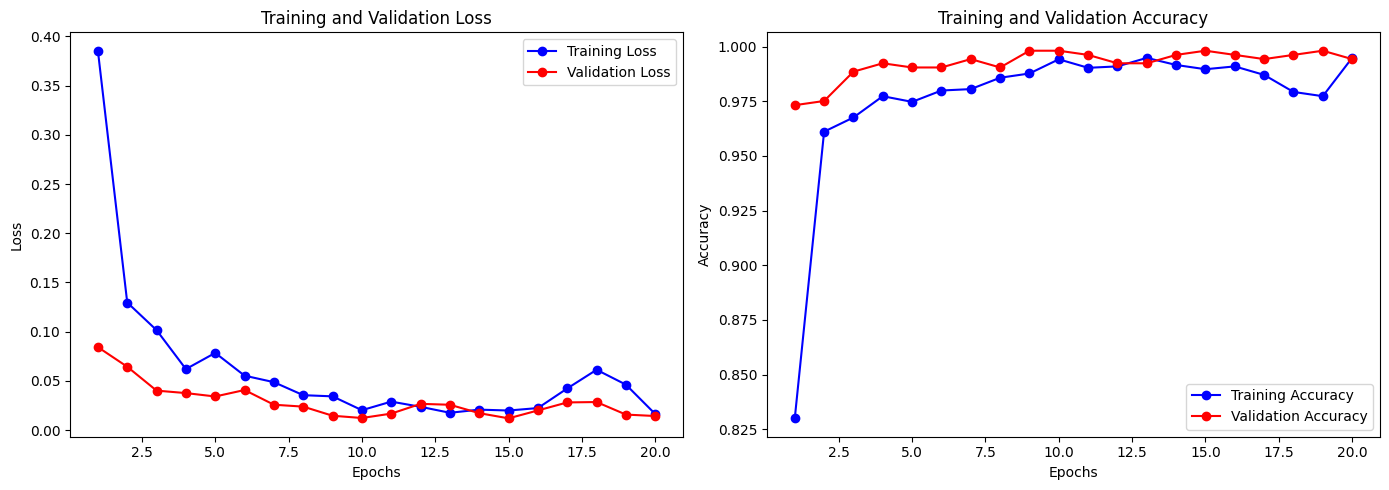

In [59]:
viz.plot_training_history(history_multimodal)

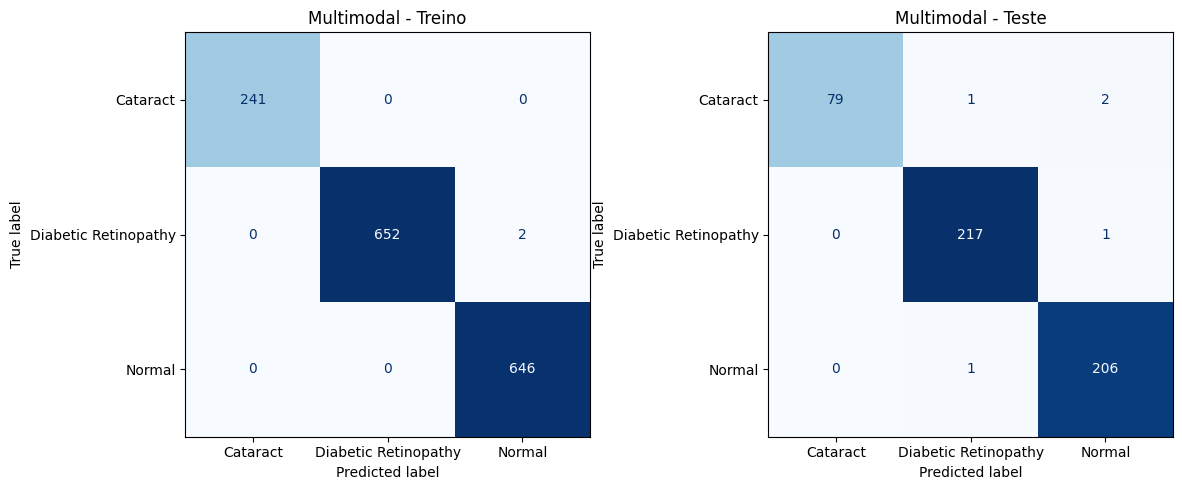

=== TREINO ===
                      precision    recall  f1-score   support

            Cataract       1.00      1.00      1.00       241
Diabetic Retinopathy       1.00      1.00      1.00       654
              Normal       1.00      1.00      1.00       646

            accuracy                           1.00      1541
           macro avg       1.00      1.00      1.00      1541
        weighted avg       1.00      1.00      1.00      1541

=== TESTE ===
                      precision    recall  f1-score   support

            Cataract       1.00      0.96      0.98        82
Diabetic Retinopathy       0.99      1.00      0.99       218
              Normal       0.99      1.00      0.99       207

            accuracy                           0.99       507
           macro avg       0.99      0.98      0.99       507
        weighted avg       0.99      0.99      0.99       507



In [60]:
# Treino
y_pred_multi_train = np.argmax(model_multimodal.predict(
    {"image_input": X_train_tl, "text_input": X_bert_train}, verbose=0
), axis=1)

# Teste
y_pred_multi_test = np.argmax(model_multimodal.predict(
    {"image_input": X_test_tl, "text_input": X_bert_test}, verbose=0
), axis=1)

# Matrizes de confusão
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_train_tl, y_pred_multi_train),
                       display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Multimodal - Treino")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_multi_test),
                       display_labels=class_names).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Multimodal - Teste")
plt.tight_layout()
plt.show()

print("=== TREINO ===")
print(classification_report(y_train_tl, y_pred_multi_train, target_names=class_names))
print("=== TESTE ===")
print(classification_report(y_test, y_pred_multi_test, target_names=class_names))

## Persistir metricas em `artifacts/results.csv`


In [ ]:
# Persistir a metrica do multimodal em artifacts/results.csv (upsert incremental
# no mesmo ficheiro que 02/03 alimentam).
for nome, modelo, history, X_t, X_tr, y_tr, proba_te, proba_tr in modelos_treinados:
    row = data.compute_metrics_row(nome, proba_te, y_test, class_names)
    data.append_results_row(row, ARTIFACTS_DIR / "results.csv")
print("results.csv atualizado.")


## Baseline text-only (TF-IDF + Regressao Logistica)

Scaffold para uma baseline que usa **apenas** os relatorios clinicos (sem
imagem), como termo de comparacao para quantificar o contributo do texto face ao
multimodal. *Placeholder de um batch posterior -- sem analise nem execucao.*


In [ ]:
# TODO (batch posterior): baseline text-only.
#   1. TF-IDF sobre df_reports["report"] (portugues; reutilizar stop_pt).
#   2. Aplicar os mesmos indices do split (train_idx / val_idx / test_idx).
#   3. LogisticRegression multiclasse com class_weight="balanced".
#   4. Registar em results.csv via data.append_results_row para entrar na
#      tabela comparativa de 05.
# Scaffold apenas -- nao implementar nesta fase.
pass


## Discussao de leakage (texto <-> imagem)

*Placeholder de um batch posterior -- sem conteudo nesta fase.* Espaco para
discutir potencial fuga de informacao entre os relatorios e as imagens (ex.:
relatorios que citam o diagnostico) e o seu efeito na leitura do ganho multimodal.
